# GSE163558: Gastric Cancer

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-10-16
> - Modified: 2026-01-17

> - Jiang H, Yu D, Yang P, et al. Revealing the transcriptional heterogeneity of organ-specific metastasis in human gastric cancer using single-cell RNA Sequencing. Clin Transl Med. 2022; 12:e730. https://doi.org/10.1002/ctm2.730
> - [GSE163558](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE163558)
> - Gastric cancer
> - 2022-02-20

---

# Experimental Design

> - scRNA-seq: Chromium Next GEM Single Cell 3ʹ Reagent Kits v3 (10x Genomics)
> - Illumina Novaseq 6000
> - CellRanger v3.0.2
> - GRCh38

| Sample | Patient | Tumor site | Disease status | Gender | Age | Blood type |
| - | - | - | - | - | - | - |
| PT1 | Patient 1 | Stomach | Primary gastric cancer | Female | 60 | O |
| Li1 | Patient 1 | Liver | Gastric cancer liver metastasis | Female | 60 | O |
| PT2 | Patient 2 | Stomach | Primary gastric cancer | Female | 80 | O |
| NT1 | Patient 2 | Stomach | Adjacent non-tumoral | Female | 80 | O |
| O1 | Patient 3 | Ovary | Gastric cancer ovary metastasis | Female | 40 | B |
| PT3 | Patient 4 | Stomach | Primary gastric cancer | Male | 60 | O |
| Li2 | Patient 4 | Liver | Gastric cancer liver metastasis | Male | 60 | O |
| LN1 | Patient 4 | Lymph node | Gastric cancer lymph node metastasis | Male | 60 | O |
| LN2 | Patient 5 | Lymph node | Gastric cancer lymph node metastasis | Female | 80 | B |
| P1 | Patient 6 | Peritoneum | Gastric cancer peritoneum metastasis | Male | 70 | A |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(scCustomize))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/data1/single_cell_dataset/TumorBiology/Hs_GastricCancer_10X_GSE163558"

In [3]:
sc.inte <- qs2::qs_read(file.path(
    data_dir, "result", "s11_annotation_seurat_V5.qs2"))

In [4]:
sc.inte

An object of class Seurat 
26093 features across 40293 samples within 1 assay 
Active assay: RNA (26093 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 dimensional reductions calculated: pca, cca, umap, tsne

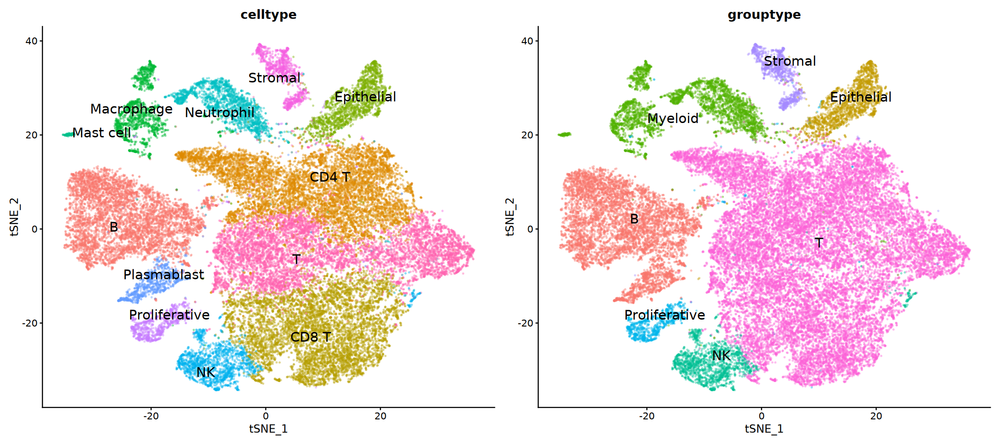

In [5]:
options(repr.plot.width = 18, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "tsne",
        group.by = c("celltype", "grouptype"), 
        label = TRUE, repel = TRUE, label.size = 6, 
        pt.size = 0.3,  alpha = 0.3) & 
    NoLegend()

# 13. T Cell Subset Analysis

In [7]:
sc.t <- subset(sc.inte, subset = grouptype == "T")
sc.t

An object of class Seurat 
26093 features across 23581 samples within 1 assay 
Active assay: RNA (26093 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 dimensional reductions calculated: pca, cca, umap, tsne

In [9]:
nPCs <- 30
inte <- "cca"

In [ ]:
# NormalizeData(sc.t, verbose = FALSE) |>
#     FindVariableFeatures(nfeatures = 2000, verbose = FALSE) |>
#     ScaleData(vars.to.regress = "percent.mt", verbose = FALSE) |>
#     RunPCA(npcs = 50, verbose = FALSE) |>
#     IntegrateLayers(method = CCAIntegration, orig.reduction = "pca", 
#                     new.reduction = "cca", verbose = FALSE) |>
#     JoinLayers() |>

In [10]:
sc.t <- FindNeighbors(sc.t, k.param = 20, reduction = inte,
                      dims = 1:nPCs, verbose = FALSE) |>
    RunUMAP(dims = 1:nPCs, reduction = inte, verbose = FALSE) |>
    RunTSNE(dims = 1:nPCs, reduction = inte, verbose = FALSE)
sc.t

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


An object of class Seurat 
26093 features across 23581 samples within 1 assay 
Active assay: RNA (26093 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 dimensional reductions calculated: pca, cca, umap, tsne

In [11]:
source("R/scan_clustering_resolution.R")

In [12]:
cluster_list <- scan_clustering_resolution(
    sc.t, reduction = inte, dims = nPCs,
    resolution = seq(0.1, 1.2, 0.1), assess = FALSE)

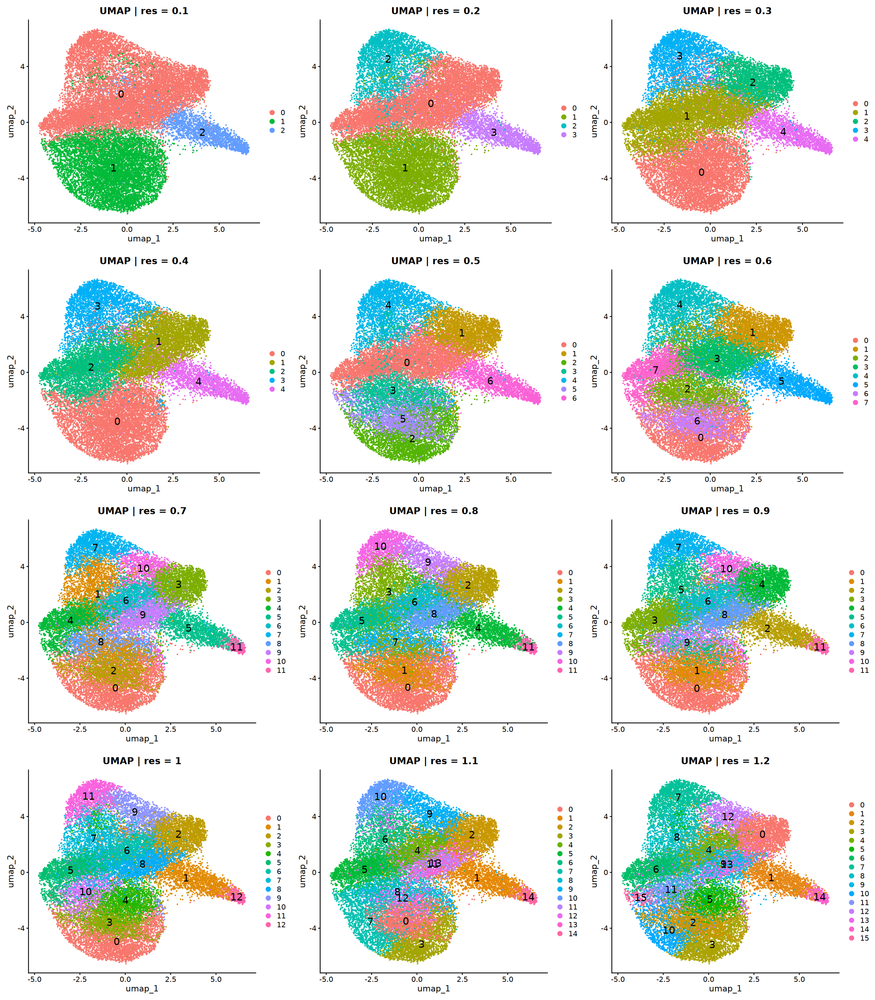

In [13]:
options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

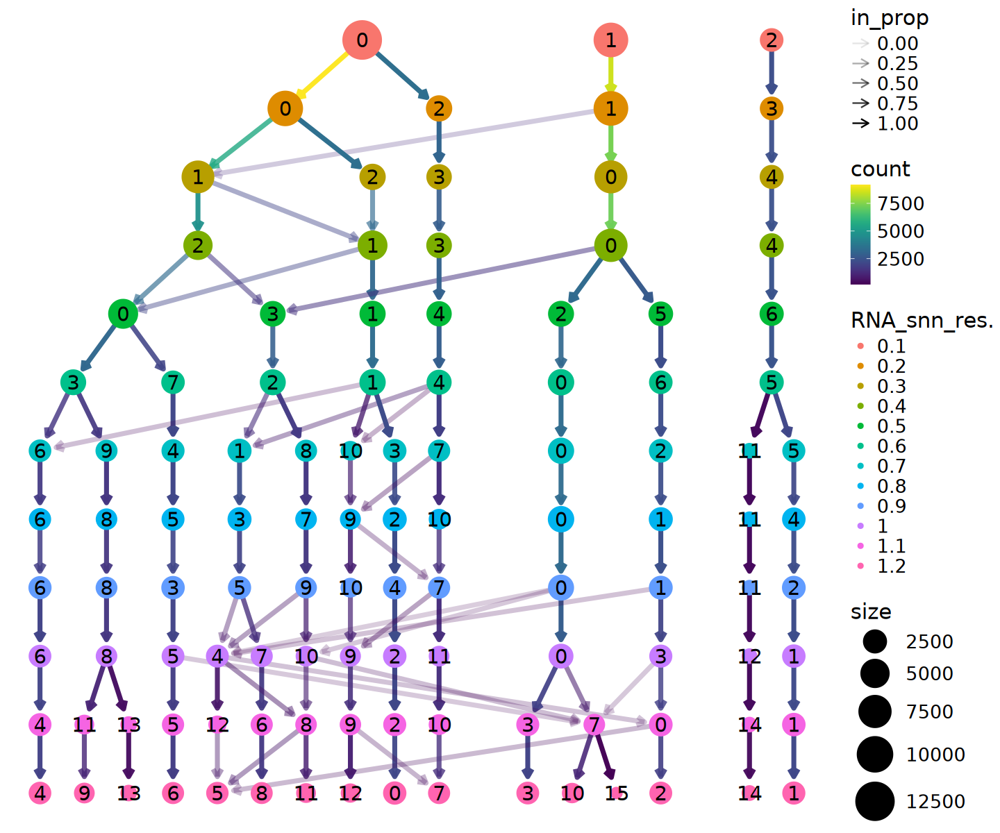

In [14]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [15]:
sc.t <- FindClusters(sc.t, resolution = 1, verbose = FALSE)

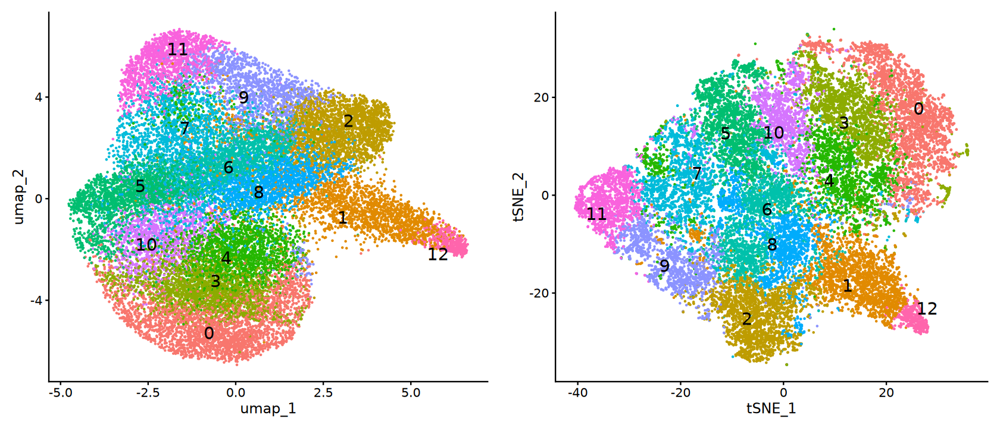

In [16]:
p1 <- DimPlot(
    sc.t, reduction = "umap", label = TRUE, repel = TRUE,
    label.size = 6) & NoLegend()
p2 <- DimPlot(
    sc.t, reduction = "tsne", label = TRUE, repel = TRUE,
    label.size = 6) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

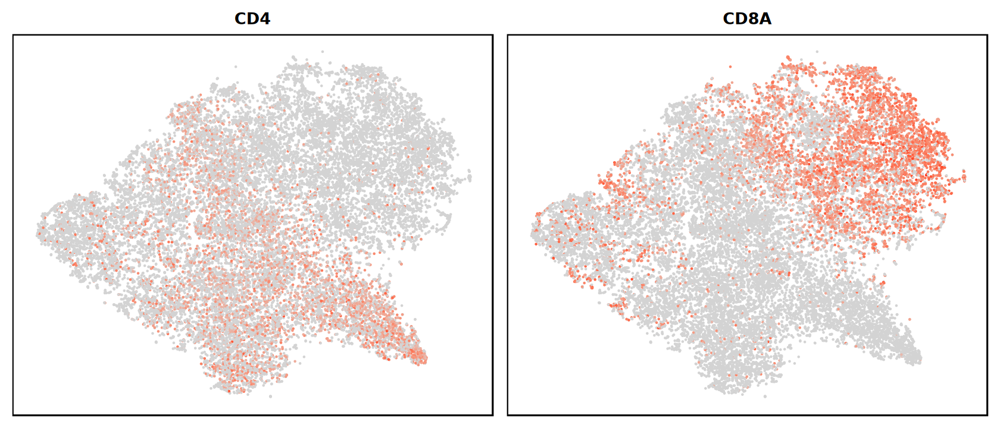

In [17]:
options(repr.plot.width = 14, repr.plot.height = 6)
FeaturePlot(sc.t, features = c("CD4", "CD8A"), 
            cols = c("lightgrey", 'red'),
            reduction = "tsne", ncol = 2) & NoLegend() & NoAxes() + 
    theme(panel.border = element_rect(color = "black", linewidth = 1))

> - naïve CD4+ T cells: "CCR7", "LEF1"
> - regulatory T cells (Treg): "CTLA4", "FOXP3"
> - exhausted CD4+ T cells: "CXCL13", "TIGIT"
> - effector memory CD4+ T cells (CD4 TEM): "CCL5", "ANXA1", "GZMA"
> - T helper type 1 CD4+ T cells (Th1): "GADD45B", "TNF"
> - naïve CD8+ T cells: "LEF1", "SELL"
> - cytotoxic CD8+ T cells: "GNLY", "GZMB"
> - exhausted CD8+ T cells: "CTLA4", "LAG3", "TIGIT"
> - effector memory CD8+ T cells (CD8 TEM): "GZMK", "CXCR4", "EOMES"
> - mucosal-associated invariant T (MAIT) cells: "SLC4A10", "KLRB1"

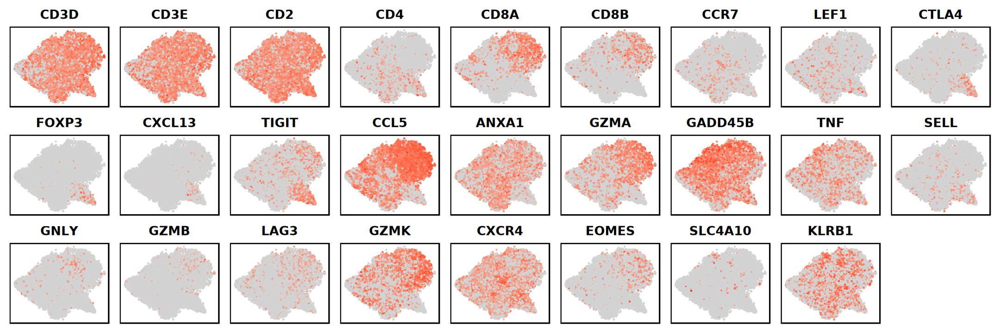

In [18]:
refMarkerGenes <- c(
    "CD3D", "CD3E", "CD2", "CD4", "CD8A", "CD8B",
    "CCR7", "LEF1", "CTLA4", "FOXP3",
    "CXCL13", "TIGIT", "CCL5", "ANXA1", "GZMA",
    "GADD45B", "TNF", "LEF1", "SELL", "GNLY", "GZMB",
    "CTLA4", "LAG3", "TIGIT", "GZMK", "CXCR4", "EOMES",
    "SLC4A10", "KLRB1"
)

options(repr.plot.width = 18, repr.plot.height = 6)
FeaturePlot(sc.t, features = refMarkerGenes, cols = c("lightgrey", 'red'),
            reduction = "tsne", ncol = 9) & NoLegend() & NoAxes() + 
    theme(panel.border = element_rect(color = "black", linewidth = 1))

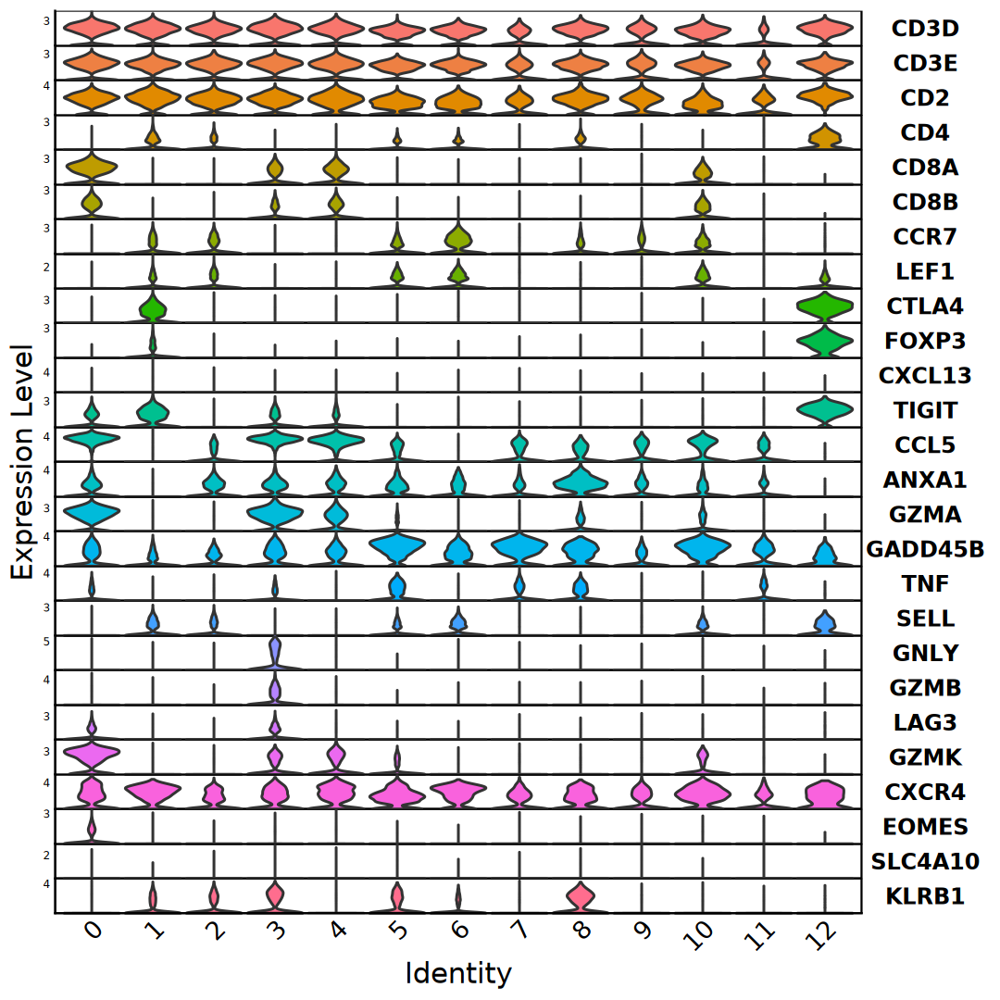

In [19]:
options(repr.plot.width = 9, repr.plot.height = 9)
VlnPlot(sc.t, features = refMarkerGenes, 
        stack = TRUE, flip = TRUE) +
    theme(legend.position = "none", 
          strip.text = element_text(size = 14),
          axis.ticks = element_blank(),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16))

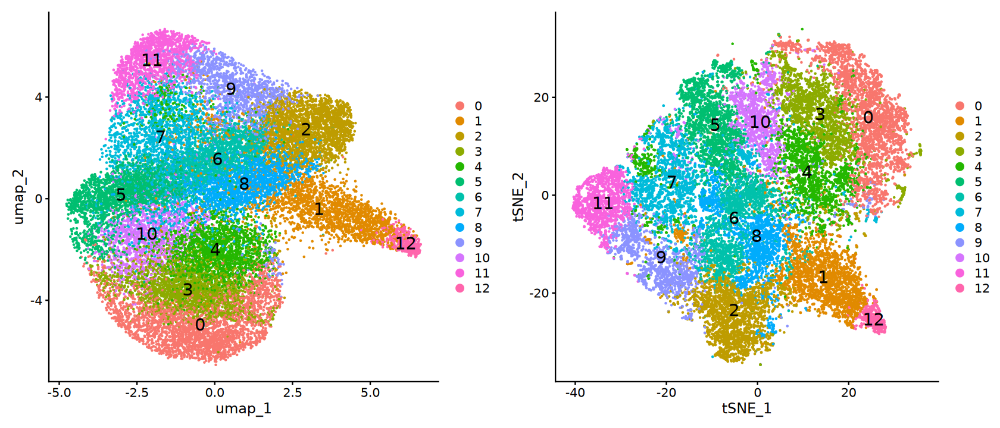

In [20]:
p1 <- DimPlot(
    sc.t, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    sc.t, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [67]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "CD8 TEM", "1" = "Exhausted CD4+ T", "2" = "Naïve CD4+ T",
    "3" = "Exhausted CD8+ T", "4" = "CD8 TEM", "5" = "Th1", 
    "6" = "Naïve CD8+ T", "7" = "CD4- CD8- T", "8" = "MAIT",
    "9" = "CD4- CD8- T", "10" = "Naïve CD8+ T", "11" = "CD4- CD8- T",
    "12" = "Treg")



Cytotoxic CD8+ T

In [68]:
sc.t@meta.data$T_celltype <- 
    cluster2celltype[as.character(sc.t$seurat_clusters)]

sc.t <- RenameIdents(sc.t, cluster2celltype)

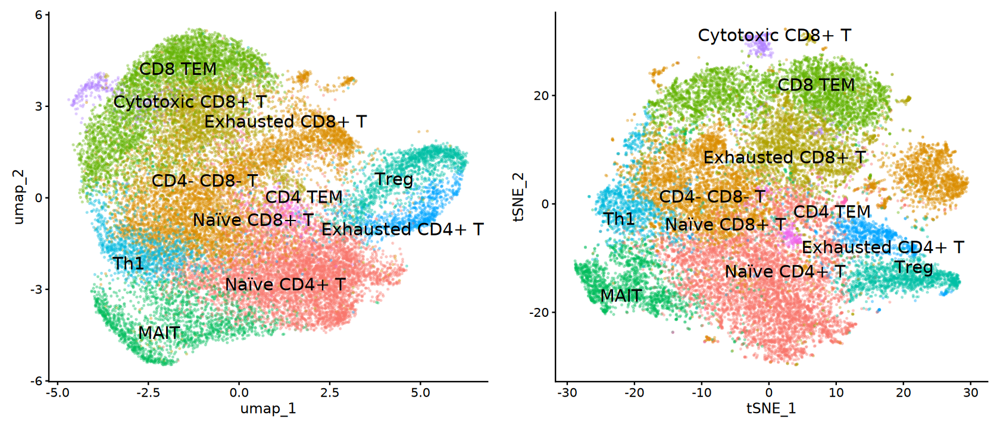

In [72]:
options(repr.plot.width = 9, repr.plot.height = 8)
p1 <- DimPlot(
    sc.t, reduction = "umap", label = TRUE, 
    label.size = 6, repel = TRUE, 
    pt.size = 0.3,  alpha = 0.3) & NoLegend()
p2 <- DimPlot(
    sc.t, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = TRUE,
    pt.size = 0.3,  alpha = 0.3) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)